# Lab 12 extra: How to split documents into chunks and measure a search

**Going further, for Lab 12**

## Goal

The two main notebooks of this lab stored short files whole and judged the search one question at a time. This
notebook goes further on both. A company handbook arrives as one long text, so we split it into **chunks**, the
pieces that get one vector each, and see what a careless split breaks. Then we measure the search over ten
questions written before searching, with whole policies and with paragraph chunks, and test a tempting guard: refuse
when the best score is low. Last, we run Chroma as a server from a terminal, so any program can search the same
store.

## What you will learn

- How to split a long text at its headings and paragraphs, with ids that point back to the source, and what a split
  every N characters breaks.
- How to measure retrieval with hit@1 and hit@3 on labelled questions, and compare two ways of chunking.
- Why a score threshold is a weak guard against questions that nothing answers.
- How to start a Chroma server with `chroma run`, and store and search through `HttpClient`.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model names from `models.env`, and
takes the key from `.env` without printing it. This notebook calls only the embedding model, a few times.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


In [2]:
import numpy as np
from openai import OpenAI

client = OpenAI(timeout=60)
EMBEDDING_MODEL = settings["EMBEDDING_MODEL"]

---

## Part A: Split a long document into chunks tagged with their source

The shop's 20 policies are 20 short files, one topic each. A real handbook is often one long document. One vector for
all of it would average every topic into one point, and a search could only ever answer "the handbook". So long
documents are split into chunks, and we tag every chunk with where it came from, so an answer can be traced back.

To see what can go wrong, we build a handbook in memory: the 20 policies joined into one text, as if they had arrived
as one document. Nothing is written to disk.

In [3]:
policy_files = sorted((ROOT / "data" / "corpus").glob("policy_*.md"))
handbook = "\n\n".join(p.read_text().strip() for p in policy_files)

print(len(policy_files), "policies joined:", len(handbook), "characters")
print(handbook[:300])

20 policies joined: 6649 characters
# Accounts

An account is the email plus the customer record. One email, one account.

A customer can change their email once per calendar year. Invoices already issued keep the old email as a snapshot.

Account deletion: we remove the login and the marketing flag. Invoices stay. Support tickets sta


One string of 6,649 characters. Each policy still starts with its `# ` heading line, but the file names are gone: from here on, only
the text says which policy a sentence belongs to.

### A split every 300 characters

The simplest split cuts at fixed positions. `range(0, len(handbook), SIZE)` gives the start positions 0, 300, 600 and
so on, and `handbook[start:start + SIZE]` takes the 300 characters from each. Each chunk's id records its range.

In [4]:
SIZE = 300
size_chunks = []
for start in range(0, len(handbook), SIZE):
    size_chunks.append({"id": f"handbook[{start}:{start + SIZE}]", "text": handbook[start:start + SIZE]})

print(len(size_chunks), "chunks")
for chunk in size_chunks[2:4]:
    print("---", chunk["id"])
    print(chunk["text"])

23 chunks
--- handbook[600:900]
o cancel, write to support with the invoice number the same day if you can.

# Damaged media

If a CD or vinyl arrives cracked, warped, or will not play, we replace it at no charge. Photograph the damage. Keep the original copy until the replacement arrives, then recycle it.

If the same title arriv
--- handbook[900:1200]
es damaged twice, offer a refund instead of a third copy.

# Data retention

Invoices: kept for 7 years (tax).

Support tickets: 24 months, then deleted.

Download logs: 12 months.

Marketing flags: until the customer opts out or the account is deleted.

We do not keep call recordings. This shop's s


23 chunks. Read where chunk `handbook[600:900]` ends and the next one starts: *"If the same title arriv"* and *"es damaged twice, offer a refund instead of a third copy."* The split has cut a rule in half:

1. Neither chunk holds the whole rule, so a search can find only half of it.
2. The second half has lost its heading. Nothing in it says which policy "offer a refund" belongs to; a model reading
   it sees a refund rule with no subject.
3. Its id points to a range of characters, not to a policy a rep could open and check.

### A split at headings, then at paragraphs

The handbook has a structure the size split ignored: every policy starts with a line beginning `# `, and its rules are
paragraphs separated by blank lines. Two loops use it:

1. Walk the lines; a heading starts a new section, and every line, the heading too, joins the current section.
2. Split each section's body (its lines after the heading, `[1:]`) at blank lines (`"\n\n"`) into paragraphs,
   skipping empty pieces. Each paragraph becomes a chunk that **starts
   with its heading** (`"Damaged media: If the same title ..."`), so its text always names its policy, with an id that
   points back to the section and the paragraph's position (`Damaged media#1`).

In [5]:
sections = []
for line in handbook.splitlines():
    if line.startswith("# "):
        sections.append({"title": line[2:], "lines": []})
    sections[-1]["lines"].append(line)

paragraphs = []
for section in sections:
    body = "\n".join(section["lines"][1:]).strip()
    for number, text in enumerate(p.strip() for p in body.split("\n\n") if p.strip()):
        paragraphs.append({"id": f"{section['title']}#{number}", "section": section["title"],
                           "text": f"{section['title']}: {text}"})

print(len(sections), "sections,", len(paragraphs), "paragraph chunks")
for chunk in paragraphs:
    if chunk["section"] == "Damaged media":
        print(chunk)

20 sections, 67 paragraph chunks
{'id': 'Damaged media#0', 'section': 'Damaged media', 'text': 'Damaged media: If a CD or vinyl arrives cracked, warped, or will not play, we replace it at no charge. Photograph the damage. Keep the original copy until the replacement arrives, then recycle it.'}
{'id': 'Damaged media#1', 'section': 'Damaged media', 'text': 'Damaged media: If the same title arrives damaged twice, offer a refund instead of a third copy.'}


20 sections and 67 paragraph chunks. The *Damaged media* section gives two: `Damaged media#0`, the replacement rule, and `Damaged media#1`, the damaged-twice rule, whole and with its heading in front.

Each chunk is a dictionary with three fields:

| Field | Holds | Who reads it |
|---|---|---|
| `id` | `Damaged media#1`: the section and the paragraph's position | our code, to find the chunk again and to cite it |
| `section` | `Damaged media`: the heading | our scoring code in Part B, and a person checking an answer |
| `text` | the heading, a colon and the paragraph | the embedding model, and later the chat model |

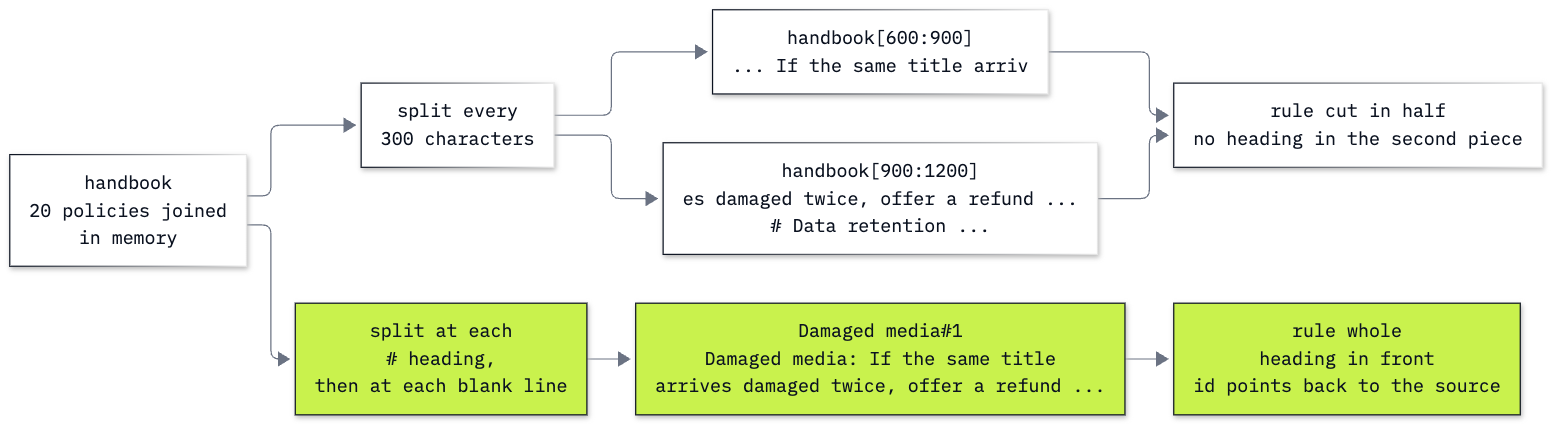

In [6]:
from IPython.display import Image

Image("resources/lab12_chunks_keep_their_source.png", width=760)

**In production:** split on the document's structure first (headings, then paragraphs), cap the chunk size, and let
neighbouring chunks overlap a little so a sentence near a boundary appears whole in one of them. LangChain's text
splitters and LlamaIndex's node parsers do this.

**Checkpoint A.** 23 chunks by size, with the damaged-twice rule cut between `handbook[600:900]` and `handbook[900:1200]`; 20 sections and 67 paragraph chunks, with `Damaged media#1` holding the rule whole.

---

## Part B: Measure the search with hit@1 and hit@3 on labelled questions

Is a paragraph a better unit to search than a whole policy? One question cannot say. We need a number over several
questions, and the answer to each written down **before any search runs**, so the search cannot shape the labels.

Below are ten questions, each with the section that answers it. Eight have an answer; two have none (`None`). Only our
scoring code reads the labels; the search sees only the question.

In [7]:
LABELLED = [
    ("How long do I have to return an unopened CD?", "Returns"),
    ("When is support staffed?", "Support hours and SLA"),
    ("Do gift cards expire?", "Gift cards"),
    ("How many business days does a refund take?", "Refunds"),
    ("My download link expired. Can I get a new one?", "Digital downloads"),
    ("Can I pay with bitcoin?", "Payment"),
    ("Is there a phone number I can call for support?", "Data retention"),
    ("Can you ship the second disc of my set separately?", "Shipping"),
    ("What is Chinook's revenue target for 2014?", None),
    ("What is the CEO's personal mobile number?", None),
]
print(sum(label is not None for _, label in LABELLED), "answerable,",
      sum(label is None for _, label in LABELLED), "unanswerable")

8 answerable, 2 unanswerable


Three questions are harder than the rest: *bitcoin* is in no policy (the payment policy says "cryptocurrency"), the phone question is
answered by one sentence at the end of the data retention policy (*"This shop's support is email only."*), and the
second-disc question by one line of the shipping policy (*"We do not split a single invoice across two parcels."*).

**hit@k** is the share of answerable questions whose labelled section is among the top `k` results:

$$\text{hit@}k = \frac{\text{answerable questions with a chunk of the right section in the top } k}{\text{answerable questions}}$$

We embed both sets of chunks, the 20 whole sections and the paragraphs, and the ten questions: three calls. Each set
becomes a matrix, one row per chunk. Every vector has length 1, so `matrix @ q` gives one cosine per chunk, as in
the main notebooks.

In [8]:
def embed_all(texts):
    return np.array([item.embedding for item in client.embeddings.create(model=EMBEDDING_MODEL, input=texts).data])


section_chunks = [{"id": s["title"], "section": s["title"], "text": "\n".join(s["lines"]).strip()} for s in sections]
CHUNKINGS = {"sections": section_chunks, "paragraphs": paragraphs}
MATRICES = {name: embed_all([c["text"] for c in chunks]) for name, chunks in CHUNKINGS.items()}
Q = embed_all([question for question, _ in LABELLED])

print({name: m.shape for name, m in MATRICES.items()}, "questions:", Q.shape)

{'sections': (20, 1536), 'paragraphs': (67, 1536)} questions: (10, 1536)


`section_chunks` holds one chunk per section, the whole policy with its heading: the same pieces as the 20 files.
Row `i` of each matrix belongs to chunk `i` of its list.

`ranked` scores every chunk of one chunking against a question and keeps the best `k`. `np.argsort(-scores)` lists
the rows from highest score to lowest (the minus sign turns "smallest first" into "highest first"), and `[:k]`
keeps the first `k`.

For each question and each chunking, `rank_of` finds the position of the first chunk from the labelled section in
the ranking (1 for first), or `None` when it is not in the top three.

In [9]:
def ranked(name, q, k):
    scores = MATRICES[name] @ q
    order = np.argsort(-scores)[:k]
    return [(CHUNKINGS[name][i], float(scores[i])) for i in order]


def rank_of(label, hits):
    sections_found = [chunk["section"] for chunk, _ in hits]
    return sections_found.index(label) + 1 if label in sections_found else None


print(f"{'question':52} {'sections':>8} {'paragraphs':>10}")
for (question, label), q in zip(LABELLED, Q):
    if label is None:
        continue
    ranks = [rank_of(label, ranked(name, q, 3)) for name in CHUNKINGS]
    print(f"{question:52} {str(ranks[0] or '-'):>8} {str(ranks[1] or '-'):>10}")

question                                             sections paragraphs
How long do I have to return an unopened CD?                1          1
When is support staffed?                                    2          1
Do gift cards expire?                                       1          1
How many business days does a refund take?                  1          1
My download link expired. Can I get a new one?              1          1
Can I pay with bitcoin?                                     1          1
Is there a phone number I can call for support?             -          2
Can you ship the second disc of my set separately?          -          1


Each number is the rank of the right section in the top three; `-` means it was not there
(`ranks[0] or '-'` prints `-` in place of `None`). Now the two measures for
each chunking:

In [10]:
for name in CHUNKINGS:
    ranks = [rank_of(label, ranked(name, q, 3)) for (_, label), q in zip(LABELLED, Q) if label is not None]
    hit1 = sum(rank == 1 for rank in ranks)
    hit3 = sum(rank is not None for rank in ranks)
    print(f"{name:11} hit@1 {hit1}/{len(ranks)} = {hit1 / len(ranks):.2f} | hit@3 {hit3}/{len(ranks)} = {hit3 / len(ranks):.2f}")

sections    hit@1 5/8 = 0.62 | hit@3 6/8 = 0.75
paragraphs  hit@1 7/8 = 0.88 | hit@3 8/8 = 1.00


With the numbers in the formula: whole sections give hit@1 = 5/8 (printed as 0.62) and hit@3 = 6/8 = 0.75; paragraphs give hit@1 = 7/8 (printed as 0.88) and hit@3 = 8/8 = 1.00.

Reading the table:

- *When is support staffed?* is second with whole sections (the representatives section comes first) and first with paragraphs: the paragraph with the hours, `Support hours and SLA#0`, no longer shares one vector with the other three rules of its policy.
- The phone and second-disc questions miss with whole sections, even at `k=3`. Each answer is one sentence inside a policy about something else, so in a whole-section vector it is one topic among several. As paragraphs, the second disc is found first (`Shipping#2`) and the phone question second.
- Five questions are first in both columns: when a policy is about one thing, the whole section is found as easily as its paragraph.

**What hit@k does not show:** it counts the right *section*, not the right *paragraph*. For the first question the top paragraph is `Returns#1`, the rule for *opened* media (14 days, and only if the disc is defective); the 30-day rule for unopened items is another paragraph. hit@1 counts it as a hit, and a model given only that chunk would answer from the wrong rule. And eight
questions we wrote ourselves are a check, not an estimate for every question a rep will ask.

**Checkpoint B.** Whole sections: hit@1 5/8 and hit@3 6/8. Paragraph chunks: hit@1 7/8 and hit@3 8/8.

---

## Part C: Test a score threshold as a guard

A tempting guard: if the best chunk's cosine is low, refuse before calling the chat model. Here are the best cosine of
every question and the best cosine of a chunk from its labelled section, for both chunkings. `k` is the number of
chunks, so the labelled section's best chunk is always in the list.

In [11]:
for name in CHUNKINGS:
    print(name)
    for (question, label), q in zip(LABELLED, Q):
        hits = ranked(name, q, len(CHUNKINGS[name]))
        best_chunk, best = hits[0]
        right = next((score for chunk, score in hits if chunk["section"] == label), None)
        right_text = f"{right:.4f}" if right is not None else "  none"
        print(f"  {question:52} {best_chunk['id']:28} {best:.4f}  right {right_text}")

sections
  How long do I have to return an unopened CD?         Returns                      0.6053  right 0.6053
  When is support staffed?                             Support representatives      0.5168  right 0.4583
  Do gift cards expire?                                Gift cards                   0.6944  right 0.6944
  How many business days does a refund take?           Refunds                      0.5064  right 0.5064
  My download link expired. Can I get a new one?       Digital downloads            0.4882  right 0.4882
  Can I pay with bitcoin?                              Payment                      0.3953  right 0.3953
  Is there a phone number I can call for support?      Support hours and SLA        0.3995  right 0.3256
  Can you ship the second disc of my set separately?   Damaged media                0.4271  right 0.3340
  What is Chinook's revenue target for 2014?           Escalations                  0.1988  right   none
  What is the CEO's personal mobile number?   

`next(..., None)` takes the first score whose chunk belongs to the labelled section, or `None` for the two questions
with no label.

- **Whole sections:** the two unanswerable questions score 0.1988 and 0.3153, and every answerable question's best chunk scores 0.3953 or more. A threshold near 0.35 would block exactly those two. But it would pass three wrong best chunks (the representatives section for the staffing question at 0.5168, the support hours for the phone question at 0.3995, damaged media for the second disc at 0.4271). And if the threshold were also used to drop every chunk below it, the right sections for the phone and second-disc questions (0.3256 and 0.3340) would be dropped while the wrong ones stayed.
- **Paragraphs:** smaller chunks raise the scores of near misses too. The CEO question's best chunk rises to 0.4676, against 0.3153 for the whole Escalations section. That chunk, `Escalations#3`, says the shop does not publish the support manager's personal phone number: close in meaning, but about a different person, and no file gives the CEO's number, so the question stays labelled with no answer. That score, 0.4676, is above the best chunks of two answerable questions, bitcoin (0.4585) and the phone question (0.4333). Any threshold that blocks the CEO question blocks those two as well.

**Key lesson:** a score says how close a chunk is, not whether it answers. A threshold set on ten questions we wrote
ourselves would be tuned to them, and the next question can fall on the wrong side. The guard that holds is the one
in the main notebooks: the generate step reads what was found and refuses.

**Checkpoint C.** With whole sections the unanswerable questions score 0.1988 and 0.3153, below every answerable question's best (0.3953 and up), while three of those best sections are wrong; with paragraphs the CEO question reaches 0.4676, above the best chunks of two answerable questions (0.4585 and 0.4333).

---

## Part D: Run Chroma as a server from a terminal

The main notebooks ran Chroma inside the notebook's process, in memory or in a folder. In practice a vector database
often runs as a **server**: one process keeps the vectors on disk, and any number of programs search it over HTTP.
Chroma's command-line tool starts one with `chroma run`.

**Start the server in a terminal.** Open a terminal in this lab's folder (`12_Retrieval`) and run:

```bash
uv run chroma run --path chroma_db/server --host 127.0.0.1 --port 8012
```

(Without `uv`, activate the repository's environment first, `source ../.venv/bin/activate`, then run the same command
from `chroma run` on.) `--path` is the folder the server keeps its data in, inside this lab's folder; the repository
ignores every `chroma_db/` folder. `--host 127.0.0.1` lets only programs on this computer connect. Chroma's default
port is 8000; we use 8012 because 8000 is often taken by another program. If 8012 is busy too, pick another number
and change `PORT` below to match.

After Chroma's logo, the terminal shows where the data goes and where to connect, then keeps running:

```text
Saving data to: chroma_db/server
Connect to Chroma at: http://localhost:8012
Getting started guide: https://docs.trychroma.com/docs/overview/getting-started
```

Leave that terminal open. The rest of this part runs here.

### Connect from the notebook

`HttpClient` is the client for a Chroma server. `heartbeat()` asks the server for its clock: a cheap "are you there?".

In [12]:
import chromadb

PORT = 8012
server = chromadb.HttpClient(host="127.0.0.1", port=PORT)
print("heartbeat:", server.heartbeat())

heartbeat: 1794476371395041000


The heartbeat is a timestamp in nanoseconds; it proves only that the server answered. If this cell raises
`ValueError: Could not connect to a Chroma server. Are you sure it is running?`, the server is not running on that
port.

The collection API is the same as in the main notebooks; only the client changed. We store the paragraph chunks with
the vectors from Part B, using `upsert`: it adds new records and replaces those whose id already exists, so running
the cell again against the data the server kept is safe. The section goes in as metadata.

In [13]:
remote = server.get_or_create_collection("handbook_paragraphs", configuration={"hnsw": {"space": "cosine"}})
remote.upsert(
    ids=[c["id"] for c in paragraphs],
    documents=[c["text"] for c in paragraphs],
    metadatas=[{"section": c["section"]} for c in paragraphs],
    embeddings=MATRICES["paragraphs"].tolist(),
)
print("stored on the server:", remote.count())

got = remote.query(query_embeddings=[Q[1].tolist()], n_results=3)
print("When is support staffed? ->", got["ids"][0])

stored on the server: 67
When is support staffed? -> ['Support hours and SLA#0', 'Support representatives#3', 'Support representatives#0']


67 paragraph chunks are stored on the server, and the staffing question finds `Support hours and SLA#0` first, as in Part B. In the terminal, each call printed a log line with its route, such as `POST /api/v2/tenants/{tenant}/databases/{database}/collections` when the collection was created. The search went over HTTP to another process and came back with the ranking of Part B.

### The server's API page

The server also serves a page that lists its API: open http://127.0.0.1:8012/docs/ in a browser. Every call
`HttpClient` made above (create a collection, upsert, query) is one of the routes listed there, and each can be tried
from the page.

> **Screenshot placeholder:** the Chroma server's API page at `/docs/`, with the collection routes open.

### Stop the server

Go back to the terminal and press **Ctrl+C**. The server stops, and its folder keeps the data: start it again with
the same command and the collection is still there. To open the same folder without a server, use
`chromadb.PersistentClient(path="chroma_db/server")` once the server has stopped.

> **⚠️ One program per folder.** Do not open a folder with `PersistentClient` while a server is using it. Stop the
> server first.

**In production:** the same pattern with a managed or self-hosted database: Pinecone, Qdrant, pgvector in
PostgreSQL, or Chroma's own hosted service.

**Checkpoint D.** The terminal shows `Saving data to: chroma_db/server`; the heartbeat prints a number; `stored on the server: 67`, and `Support hours and SLA#0` first for the staffing question.

---

## What you can do now

- Split a long text at its headings and paragraphs with ids that point back to the source, and say what a split every
  300 characters breaks (Part A).
- Write labelled questions before searching, and compute hit@1 and hit@3 for two chunkings (Part B).
- Explain, with this notebook's scores, why a score threshold is a weak guard (Part C).
- Start a Chroma server with `chroma run`, store and search through `HttpClient`, and stop it (Part D).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ValueError: Could not connect to a Chroma server. Are you sure it is running?` | no server answers on `PORT` | start the server in a terminal (Part D) and check that its `--port` matches `PORT` |
| `` error: Failed to spawn: `chroma` `` | `uv run` was started outside the repository folder | run the command from `12_Retrieval` or another folder inside the repository |
| your scores differ from ours in the third or fourth decimal | the same text embedded twice can give slightly different numbers | check the ranks, not the last digits |

## Resources

- [Chroma: client-server mode](https://docs.trychroma.com/docs/run-chroma/client-server): `chroma run` and
  `HttpClient`.
- [Chroma: query and get](https://docs.trychroma.com/docs/querying-collections/query-and-get): `query`, `n_results`
  and the shape of the result.
- [LangChain: text splitters](https://docs.langchain.com/oss/python/integrations/splitters): splitting by structure,
  size and overlap.
- [OpenAI: vector embeddings](https://developers.openai.com/api/docs/guides/embeddings): the embedding models and
  their sizes.
- [Bonus lab B6: How to move retrieval to Pinecone](../bonus/B6_Pinecone_Retrieval/README.md): the same search on Pinecone,
  a managed vector database (it needs a Pinecone account).